# Data Exploration Notebook

The goal of this notebook is to explore the given data ahead of the modeling task

## The task

The goal of the task is to perform binary classification. We should predict for each person whether they have coronoary heart disease (MICHD) from their answers to a health survey. Our target variable is **_MICHD**: it takes two values: either +1 if the respondant was told by a health professional that they had a heart attack (myocardial infection), angina or coronary heart disease or -1 otherwise

**Input and Output:** We have a training set of 328135 people x 321 features with labels. The test set contains 109379 people without the labels. We submit one prediction {-1, 1} per test ID as a CSV file on AIcrowd. For more details on the rules of submission and the expected deliverables, please check the project description 

## The Dataset

The [Behavioral Risk Factor Surveillance System (BRFSS) 2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html) is a US telephone survey about health behaviour. Each row corresponds to one person and each column represents either a raw survey answer or a variable calculated by CDC for those answers. The codebook on the official page defines every column and every value code.  We have the following files given

| File | Rows | Columns | Content |
|---|---|---|---|
| `x_train.csv` | 328,135 | `Id` + 321 features | training features |
| `y_train.csv` | 328,135 | `Id`, `_MICHD` | label in {−1, +1} |
| `x_test.csv` | 109,379 | `Id` + 321 features | test features (same columns) |
| `sample_submission.csv` | 109,379 | `Id`, `Prediction` | submission format (all −1) |

**Column names follow the BRFSS codebook**
- No prefix (`GENHLTH`, `SMOKE100`, …): the raw answer to one survey question.
- Leading underscore (`_AGEG5YR`, `_BMI5`, `_SMOKER3`, …) or trailing underscore (`MAXVO2_`, `FRUTDA1_`, …): **calculated variables**, i.e. cleaned, recoded or combined versions of raw answers. They are often the easiest columns to use.
- Columns are in questionnaire order, so neighbouring columns belong to the same topic (section 6 groups them).

**How values are coded.** Every value is a number. Empty fields (NaN) mostly mean "question not asked". The main conventions:

| Code | Meaning | Example |
|---|---|---|
| `1` / `2` | Yes / No | `CVDSTRK3` (ever had a stroke) |
| `7`, `77`, `777`, `7777` | Don't know / not sure | `GENHLTH = 7` |
| `9`, `99`, `999`, `9999` | Refused (in calculated variables: "don't know, refused or missing") | `INCOME2 = 99` |
| `8`, `88`, `888` | None / never: **a real answer, often meaning 0** | `PHYSHLTH = 88` → 0 bad days |
| `555` | Never | `FRUIT1 = 555` |
| `1xx` / `2xx` | xx per week / xx per month | `ALCDAY5 = 203` → 3 days per month |
| `9xxx` | value given in metric units | `WEIGHT2 = 9070` → 70 kg |

These codes are **not universal**: in `EMPLOY1`, `7` means *retired*, and some calculated variables use their own codes (`_AGEG5YR = 14`, `_DRNKWEK = 99900`).
Check the codebook for every feature you rely on.

## Exploring the Dataset

In [ ]:
import sys
from pathlib import Path 

import numpy as np
import matplotlib.pyplot as plt 

ROOT = Path.cwd().parent
sys.path.append(str(ROOT))
from helpers import load_csv_data
import time
import os

In [2]:
data_dir = f"{ROOT}/data"

In [3]:
start = time.time()
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_dir)
end = time.time()
print(f"Loaded in {end-start} seconds")
print("x_train:", x_train.shape, "| x_test:", x_test.shape, "| y_train:", y_train.shape)

Loaded in 149.64799547195435 seconds
x_train: (328135, 321) | x_test: (109379, 321) | y_train: (328135,)


In [4]:
# getting the feature names since load_csv_data drops the header 
with open(os.path.join(data_dir, "x_train.csv")) as train_data_reader: 
    header = train_data_reader.readline().strip().split(",")

feature_names = np.array(header[1:])
print(f"In total we have {len(feature_names)} features")
print(f"Some sample features are {feature_names[:5]}")

# name to column index mapping
name_column_index_mapping = {name: j for j, name in enumerate(feature_names)}
column_index_name_mapping = {j: name for j, name in enumerate(feature_names)}

with open(os.path.join(data_dir, "x_test.csv")) as test_data_reader: 
    header_test = test_data_reader.readline().strip().split(",")

assert header == header_test, "train and test columns differ"
assert len(feature_names) == x_train.shape[1] == x_test.shape[1], "names do not match the data"

In total we have 321 features
Some sample features are ['_STATE' 'FMONTH' 'IDATE' 'IMONTH' 'IDAY']


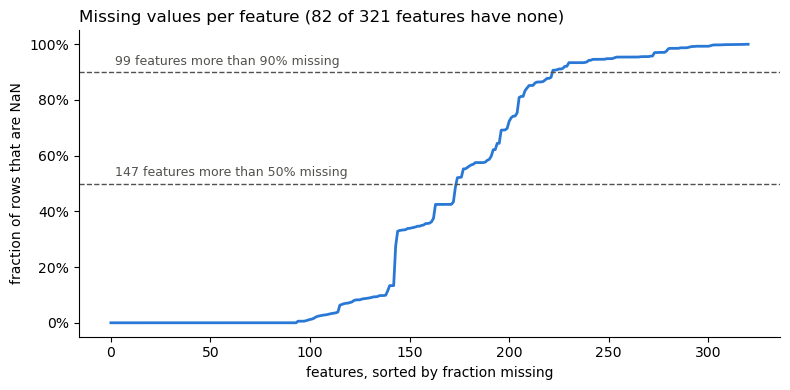

In [6]:
from matplotlib.ticker import PercentFormatter

missing_fraction = np.isnan(x_train).mean(axis=0)       # one value per feature
order = np.argsort(missing_fraction)                     # least to most missing

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(len(order)), missing_fraction[order], color="#2a78d6", lw=2)

# reference lines with the number of features above each threshold
for threshold in [0.5, 0.9]:
    n_above = (missing_fraction > threshold).sum()
    ax.axhline(threshold, color="#52514e", ls="--", lw=1)
    ax.text(2, threshold + 0.015, f"{n_above} features more than {threshold:.0%} missing",
            color="#52514e", fontsize=9, va="bottom")

ax.set_xlabel("features, sorted by fraction missing")
ax.set_ylabel("fraction of rows that are NaN")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title(f"Missing values per feature ({(missing_fraction == 0).sum()} of {len(feature_names)} features have none)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

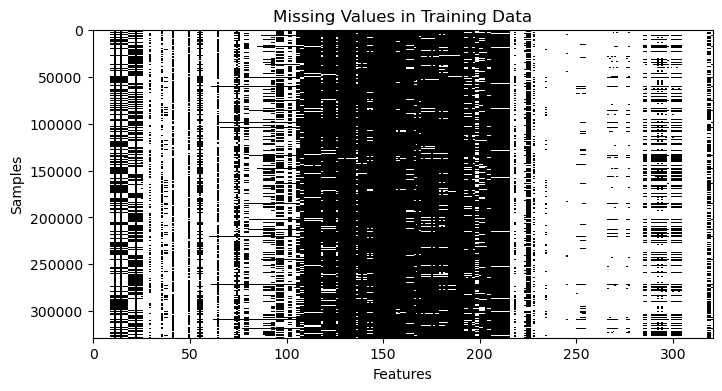

In [7]:
#Plotting the missing values as a binary matrix, making the missing values per sample more visible
missing_matrix = np.isnan(x_train)
fig, ax = plt.subplots(figsize=(8, 4))
ax.imshow(missing_matrix, aspect="auto", cmap="gray_r", interpolation="nearest")
ax.set_xlabel("Features")
ax.set_ylabel("Samples")
ax.set_title("Missing Values in Training Data")
plt.show()

In [77]:

# Quantitative variables identified from the BRFSS 2015 codebook
missingness = missing_matrix.mean(axis=0)  # fraction of missing values per feature


# not in our data: PAINACT2, QLMENTL2, QLSTRES2,  QLHLTH2,
numerical_variables = [
    # Household counts
    "NUMADULT", "NUMMEN", "NUMWOMEN", "HHADULT", "CHILDREN",
    "_CHLDCNT",

    # Health-related number of days
    "PHYSHLTH", "MENTHLTH", "POORHLTH",
    "ASACTLIM",
    "ADPLEASR", "ADDOWN", "ADSLEEP", "ADENERGY",
    "ADEAT1", "ADFAIL", "ADTHINK", "ADMOVE",

    # Ages and anthropometric measurements
    "DIABAGE2", "ASTHMAGE", "_AGE80",
    "WEIGHT2", "HEIGHT3", "HTIN4", "HTM4", "WTKG3", "_BMI5",

    # Counts of visits, tests, or treatments
    "DOCTDIAB", "CHKHEMO3", "FEETCHK",
    "ASERVIST", "ASDRVIST", "ASRCHKUP", "HPVADSHT",

    # Work hours
    "SCNTWRK1", "SCNTLWK1",

    # Alcohol consumption quantities
    "AVEDRNK2", "DRNK3GE5", "MAXDRNKS",
    "DROCDY3_", "_DRNKWEK", "ALCDAY5", #Contained in other vars

    # Food consumption frequencies and derived totals
    "FTJUDA1_", "FRUTDA1_", "BEANDAY_",
    "GRENDAY_", "ORNGDAY_", "VEGEDA1_",
    "_FRUTSUM", "_VEGESUM", # Probably is contained in "FRUTDA1_" "FRUIT1", same for "VEGETAB1", "FVGREEN", "FRUITJU1", "FVBEANS", "FVORANG"

    # Physical activity measurements and estimates
    "METVL11_", "METVL21_", "MAXVO2_", "FC60_",
    "PADUR1_", "PADUR2_", "PAFREQ1_", "PAFREQ2_",
    "_MINAC11", "_MINAC21", "STRFREQ_",
    "PAMIN11_", "PAMIN21_", "PA1MIN_",
    "PAVIG11_", "PAVIG21_", "PA1VIGM_", "EXERHMM1",
    "EXERHMM2",  # Contained in other var "EXEROFT1","STRENGTH", "EXEROFT2"

    # Survey weights (quantitative, but normally excluded from FAMD)
    "_STRWT", "_RAWRAKE", "_WT2RAKE", "_LLCPWT",
    "_CLLCPWT", "_DUALCOR",
]

var_to_exclude = ["_LLCPWT","SEQNO",  "_PSU", "_STSTR", "IDATE", "FRUIT1", "VEGETAB1","FVGREEN", 
                  "FRUITJU1", "FVBEANS", "FVORANG", "STRENGTH", "EXEROFT1", "EXEROFT2", "IDAY",
                  "FLSHTMY2","FMONTH","IMONTH", "CTELENUM", "STATERES", "CTELNUM1", "CELLFON2",
                  ]
ids_to_exclude = [name_column_index_mapping[v] for v in var_to_exclude]

name_column_mapping_X = {}
column_name_mapping_X = {}
threshold_missingness = 0.25  # threshold for missingness to include variable in mapping

X = x_train[:, :0]
k=0
for name in numerical_variables:
    if missingness[name_column_index_mapping[name]] < threshold_missingness:
        name_column_mapping_X[name] = k
        column_name_mapping_X[k] = name
        k += 1
        ids_to_exclude.append(name_column_index_mapping[name])
        X=np.column_stack((X, x_train[:, name_column_index_mapping[name]]))

def impute_missing_values(C, cat=False):
    A = np.copy(C)
    for c in range(A.shape[-1]):
        if cat:
            A[:, c] = np.where(np.isnan(A[:,c]), np.nanmedian(A[:,c]), A[:,c])
        else:
            A[:, c] = np.where(np.isnan(A[:,c]), 0, A[:,c])
    return A

X = impute_missing_values(X)


name_column_mapping_G = {}
column_name_mapping_G = {}

G = x_train[:, :0]
k=0
for id in name_column_index_mapping.values():
    if id not in ids_to_exclude and missingness[id] < threshold_missingness:
        name_column_mapping_G[column_index_name_mapping[id]] = k
        column_name_mapping_G[k] = column_index_name_mapping[id]
        k += 1
        G=np.column_stack((G, x_train[:, id]))

G = impute_missing_values(G, cat=True)

print(f"X shape: {X.shape} | G shape: {G.shape}")


X shape: (328135, 29) | G shape: (328135, 100)


In [ ]:
# Standardize the quantitative variables in X to have mean 0 and standard deviation 1
m_X = np.nanmean(X, axis=0)
std_X = np.nanstd(X, axis=0)

z_X = (X - m_X) / std_X


# Determine the number of one-hot columns first
categorical_info = []
n_one_hot_columns = 0

n_max=0
name_max = None
n_min=200
name_min = None
for name, col_idx in name_column_mapping_G.items():
    values, inverse = np.unique(
        G[:, col_idx],
        return_inverse=True
    )

    N = len(values)

    if n_max<N and N<10:
        n_max=N
        name_max = name

    if n_min>N :
        n_min=N
        name_min = name

    categorical_info.append((name, values, inverse))
    n_one_hot_columns += len(values)

print(f"Name of the column with the most categories: {name_max} Max number of categories: {n_max}")
print(f"Name of the column with the least categories: {name_min} Min number of categories: {n_min}")


In [ ]:
# One-hot encode the categorical variables in G
n_rows = G.shape[0]
G1 = np.zeros((n_rows, n_one_hot_columns))

weight = np.ones_like(G1[0])


name_column_mapping_G1 = {}
column_name_mapping_G1 = {}

column_idx = 0

for name, values, inverse in categorical_info:
    n_values = len(values)
    columns = np.arange(column_idx, column_idx + n_values)
    
    # Fill the appropriate one-hot column for each row
    G1[np.arange(n_rows), columns[inverse]] = 1.0

    weight[columns] = 1 / np.sqrt(n_values-1)
    for value, output_column in zip(values, columns):
        feature_name = f"{name}_{value}"
        name_column_mapping_G1[feature_name] = int(output_column)
        column_name_mapping_G1[int(output_column)] = feature_name

    column_idx += n_values


# Normalize categorical variables
m_G1 = np.mean(G1, axis=0)


#Y = (G1 - m_G1)*weight
Y = (G1 - m_G1)/np.sqrt(m_G1)

print(f"Z shape: {z_X.shape} | Y shape: {Y.shape}")

In [ ]:
# Perform the FAMD
M = np.column_stack((z_X, Y))

U, S, Vh = np.linalg.svd(M, full_matrices=False)
V = Vh.T


In [ ]:
print(f"U shape: {U.shape} | S shape: {S.shape} | V shape: {V.shape}")

F = U[:,:2]*S[:2]

print(f"F shape: {F.shape}")

In [ ]:
#Visualize the 2D projection of the data onto the first two principal components with colors representing the heart disease label

fig, ax = plt.subplots(figsize=(8, 6))

for label, color, name in [
    (-1, "tab:blue", "No heart disease"),
    (1, "tab:red", "Heart disease"),
]:
    mask = y_train == label
    ax.scatter(
        F[mask, 0],
        F[mask, 1],
        color=color,
        alpha=0.5,
        label=f"{name} ({label})"
    )

ax.set_xlabel("First Principal Component")
ax.set_ylabel("Second Principal Component")
ax.set_title("2D Projection of Data onto First Two Principal Components")
ax.legend(title="Class")
plt.tight_layout()
plt.show()

In [ ]:

def plot_2d_projection(F, y, pc1=0, pc2=1):
    fig, ax = plt.subplots(figsize=(8, 6))
    for label, color, name in [
        (-1, "tab:blue", "No heart disease"),
        (1, "tab:red", "Heart disease"),
    ]:
        mask = y == label
        ax.scatter(
            F[mask, pc1],
            F[mask, pc2],
            color=color,
            alpha=0.5,
            label=f"{name} ({label})"
        )

    ax.set_xlabel(f"Principal Component {pc1 + 1}")
    ax.set_ylabel(f"Principal Component {pc2 + 1}")
    ax.set_title("2D Projection of Data onto First Two Principal Components")
    ax.legend(title="Class")
    plt.tight_layout()
    plt.show()

In [ ]:

F = U*S
for i in range(len(S)):
    plot_2d_projection(F, y_train, pc1=i, pc2=(i+1))

# Missing values Imputation 
Next cell is for imputation of missing values using MICE implement with numpy and used numba njit to try to speed it up. 

#### **It takes around 20min per imputed dataset**. 

In [ ]:
import timeit

# Quantitative variables identified from the BRFSS 2015 codebook
missingness = missing_matrix.mean(axis=0)  # fraction of missing values per feature


# not in our data: PAINACT2, QLMENTL2, QLSTRES2,  QLHLTH2,
numerical_variables = [
    # Household counts
    "NUMADULT", "NUMMEN", "NUMWOMEN", "HHADULT", "CHILDREN",
    "_CHLDCNT",

    # Health-related number of days
    "PHYSHLTH", "MENTHLTH", "POORHLTH",
    "ASACTLIM",
    "ADPLEASR", "ADDOWN", "ADSLEEP", "ADENERGY",
    "ADEAT1", "ADFAIL", "ADTHINK", "ADMOVE",

    # Ages and anthropometric measurements
    "DIABAGE2", "ASTHMAGE", "_AGE80",
    "WEIGHT2", "HEIGHT3", "HTIN4", "HTM4", "WTKG3", "_BMI5",

    # Counts of visits, tests, or treatments
    "DOCTDIAB", "CHKHEMO3", "FEETCHK",
    "ASERVIST", "ASDRVIST", "ASRCHKUP", "HPVADSHT",

    # Work hours
    "SCNTWRK1", "SCNTLWK1",

    # Alcohol consumption quantities
    "AVEDRNK2", "DRNK3GE5", "MAXDRNKS",
    "DROCDY3_", "_DRNKWEK", "ALCDAY5", #Contained in other vars

    # Food consumption frequencies and derived totals
    "FTJUDA1_", "FRUTDA1_", "BEANDAY_",
    "GRENDAY_", "ORNGDAY_", "VEGEDA1_",
    "_FRUTSUM", "_VEGESUM", # Probably is contained in "FRUTDA1_" "FRUIT1", same for "VEGETAB1", "FVGREEN", "FRUITJU1", "FVBEANS", "FVORANG"

    # Physical activity measurements and estimates
    "METVL11_", "METVL21_", "MAXVO2_", "FC60_",
    "PADUR1_", "PADUR2_", "PAFREQ1_", "PAFREQ2_",
    "_MINAC11", "_MINAC21", "STRFREQ_",
    "PAMIN11_", "PAMIN21_", "PA1MIN_",
    "PAVIG11_", "PAVIG21_", "PA1VIGM_", "EXERHMM1",
    "EXERHMM2",  # Contained in other var "EXEROFT1","STRENGTH", "EXEROFT2"
]

var_to_exclude = ["_LLCPWT","SEQNO",  "_PSU", "_STSTR", "IDATE", "FRUIT1", "VEGETAB1","FVGREEN", 
                  "FRUITJU1", "FVBEANS", "FVORANG", "STRENGTH", "EXEROFT1", "EXEROFT2", "IDAY",
                  "FLSHTMY2","FMONTH","IMONTH", "CTELENUM", "STATERES", "CTELNUM1", "CELLFON2",
                  "_STRWT", "_RAWRAKE", "_WT2RAKE", "_LLCPWT", "_CLLCPWT", "_DUALCOR"]
ids_to_exclude = [name_column_index_mapping[v] for v in var_to_exclude]


cat_name_idx_map = {}

num_name_idx_map = {}

num_idx = []
cat_idx = []

threshold_missingness = 0.5  # threshold for missingness to include variable in mapping
k=0
j=0
for name, index in name_column_index_mapping.items():
    if missingness[index]<=threshold_missingness:
        if name in numerical_variables:
            num_name_idx_map[name] = k
            num_idx.append(index)
            k+=1
        elif name not in var_to_exclude:
            cat_name_idx_map[name] = j
            cat_idx.append(index)
            j+=1


cat_name_idx_map = {name: idx+len(num_idx) for name, idx in cat_name_idx_map.items()}

Xraw = np.column_stack((x_train[:, num_idx], np.column_stack((x_train[:, cat_idx], y_train))))

num_idx = list(range(len(num_idx)))
cat_idx = list(range(len(num_idx), Xraw.shape[1]))


# ----------------------------------------------------------------------
# 1. Conversion helpers
# ----------------------------------------------------------------------
def to_codes(Xraw, cat_idx):
    X = np.asarray(Xraw, dtype=float).copy()
    levels, K = {}, [0] * X.shape[1]
    for j in cat_idx:
        obs = ~np.isnan(X[:, j])
        lv = np.unique(X[obs, j])
        X[obs, j] = np.searchsorted(lv, X[obs, j])
        levels[j], K[j] = lv, len(lv)
    return X, levels, K

def from_codes(Xi, levels):
    out = Xi.copy()
    for j, lv in levels.items():
        out[:, j] = lv[Xi[:, j].astype(int)]
    return out

def one_hot(Xi, num_idx, cat_idx, K):
    parts = [Xi[:, num_idx]]
    for j in cat_idx:
        parts.append(np.eye(K[j])[Xi[:, j].astype(int)])
    return np.hstack(parts)

# ----------------------------------------------------------------------
# 2. Imputation models (all observed rows are used)
# ----------------------------------------------------------------------

def _impute_num(A_fit, y_fit, A_miss, rng, ridge=1e-4):
    n, p = A_fit.shape

    G = A_fit.T @ A_fit
    Xt_y = A_fit.T @ y_fit

    scale = ridge * np.trace(G) / p
    G.flat[::p + 1] += scale
    G[0, 0] -= scale

    L = np.linalg.cholesky(G)

    beta_hat = np.linalg.solve(
        L.T,
        np.linalg.solve(L, Xt_y),
    )

    residuals = y_fit - A_fit @ beta_hat
    sigma2 = (residuals @ residuals) / rng.chisquare(max(n - p, 1))

    beta = beta_hat + np.sqrt(sigma2) * np.linalg.solve(
        L.T,
        rng.standard_normal(p),
    )

    return (
        A_miss @ beta
        + np.sqrt(sigma2) * rng.standard_normal(A_miss.shape[0])
    )


def _impute_cat(A_fit, y_fit, A_miss, K, rng, lam=1.0):
    n_obs = A_fit.shape[0]

    bootstrap_indices = rng.integers(
        0,
        n_obs,
        size=n_obs,
    )
    counts = np.bincount(
        bootstrap_indices,
        minlength=n_obs,
    )

    selected = counts > 0
    As = A_fit[selected]
    labels = y_fit[selected].astype(np.int64)
    weights = counts[selected].astype(A_fit.dtype, copy=False)

    weighted_As = As * weights[:, None]
    XtX = As.T @ weighted_As

    XtY = np.zeros(
        (As.shape[0], K),
        dtype=A_fit.dtype,
    )
    XtY[np.arange(As.shape[0]), labels] = weights
    XtY = As.T @ XtY

    p = XtX.shape[0]
    XtX.flat[::p + 1] += lam
    XtX[0, 0] -= lam

    W = np.linalg.solve(XtX, XtY)

    P = np.clip(A_miss @ W, 1e-3, None)
    P /= P.sum(axis=1, keepdims=True)

    u = rng.random(A_miss.shape[0])
    draw = np.sum(P.cumsum(axis=1) < u[:, None], axis=1)

    return np.minimum(draw, K - 1)

def fill_numba(D, Xi, j, is_num, start, k, mu, sd):
    n = Xi.shape[0]

    if is_num:
        for i in range(n):
            D[i, start] = (Xi[i, j] - mu[j]) / sd[j]
    else:
        for i in range(n):
            value = int(Xi[i, j])

            for c in range(1, k):
                D[i, start + c - 1] = 1.0 if value == c else 0.0

# ----------------------------------------------------------------------
# 3. One chain = one completed dataset
# ----------------------------------------------------------------------
def _chain(X, types, K, n_iter, seed, max_fit_rows):
    start_time = timeit.default_timer()

    rng = np.random.default_rng(seed)
    n, d = X.shape
    Mk = np.isnan(X)
    order = [j for j in np.argsort(Mk.sum(0), kind='stable') if Mk[:, j].any()]
    # design matrix D: column 0 = intercept, then one slice per variable
    slices, start = [], 1
    for t, k in zip(types, K):
        w = 1 if t == 'num' else max(k - 1, 0)
        slices.append(slice(start, start + w))
        start += w
    keep = [np.concatenate([[0]] + [np.arange(s.start, s.stop)
            for i, s in enumerate(slices) if i != j]) for j in range(d)]

    # fixed standardization of numeric columns (computed once)
    mu = np.array([np.nanmean(X[:, j]) if types[j] == 'num' else 0. for j in range(d)])
    sd = np.array([np.nanstd(X[:, j]) + 1e-12 if types[j] == 'num' else 1. for j in range(d)])

    is_num = np.array([t == "num" for t in types], dtype=np.bool_)
    slice_start = np.array([s.start for s in slices], dtype=np.int64)
    K_array = np.asarray(K, dtype=np.int64)

    Xi = X.copy()
    for j in order:                                            # random initial fill
        Xi[Mk[:, j], j] = rng.choice(X[~Mk[:, j], j], size=Mk[:, j].sum())
    D = np.ones((n, start))
    for j in range(d):
        #fill(D, Xi, j)
        fill_numba(D, Xi, j, is_num[j], slice_start[j], K_array[j], mu, sd)



    for _ in range(n_iter):
        for j in order:
            #t0 = timeit.default_timer()
            p_j = len(keep[j])

            missing_rows = np.flatnonzero(Mk[:, j])
            observed_rows = np.flatnonzero(~Mk[:, j])

            if observed_rows.size > max_fit_rows:
                fit_rows = rng.choice(
                    observed_rows,
                    size=max_fit_rows,
                    replace=False,
                )
            else:
                fit_rows = observed_rows

            A_fit = D[np.ix_(fit_rows, keep[j])]
            A_miss = D[np.ix_(missing_rows, keep[j])]

            if types[j] == "num":
                Xi[missing_rows, j] = _impute_num(
                    A_fit,
                    Xi[fit_rows, j],
                    A_miss,
                    rng,
                )
                #t1 = timeit.default_timer()
                #print(f"Imputed numeric column {j} in {t1-t0:.2f} seconds")
            else:
                Xi[missing_rows, j] = _impute_cat(
                    A_fit,
                    Xi[fit_rows, j],
                    A_miss,
                    K[j],
                    rng,
                )
                #t1 = timeit.default_timer()
                #print(f"Imputed categorical column {j} in {t1-t0:.2f} seconds")
            fill_numba(D, Xi, j, is_num[j], slice_start[j], K_array[j], mu, sd)     # refresh only column j

    elapsed = timeit.default_timer() - start_time
    print(f"Chain completed in {elapsed:.1f} seconds")
    return Xi

def mice(X, types, K, m=5, n_iter=5, seed=0, max_fit_rows=75000):
    master = np.random.default_rng(seed)
    return [_chain(X, types, K, n_iter, int(master.integers(2**32)), max_fit_rows) for _ in range(m)]

# ----------------------------------------------------------------------
# 4. Run
# ----------------------------------------------------------------------
d = Xraw.shape[1]
assert not set(num_idx) & set(cat_idx), "num_idx and cat_idx overlap"
assert sorted(num_idx + cat_idx) == list(range(d)), "every column must be in exactly one list"
types = ['num' if j in num_idx else 'cat' for j in range(d)]

X, levels, K = to_codes(Xraw, cat_idx)
imputed = mice(X, types, K, m=3, n_iter=5, seed=67)

completed    = [from_codes(Xi, levels) for Xi in imputed]
completed_oh = [one_hot(Xi, num_idx, cat_idx, K) for Xi in imputed]

mask = np.isnan(Xraw)
assert all(not np.isnan(c).any() for c in completed)
assert all(np.allclose(c[~mask], Xraw[~mask]) for c in completed)
print(len(completed), "datasets, shape", completed[0].shape, "| one-hot shape", completed_oh[0].shape)

Chain completed in 730.4 seconds
Chain completed in 689.9 seconds
Chain completed in 684.3 seconds
3 datasets, shape (328135, 158) | one-hot shape (328135, 712)


In [58]:


name_column_mapping_M = num_name_idx_map.copy()
groups = []

def one_hot_encode_M(Xi, i, num_idx, cat_dict,  prop_scaling = False):
    global groups
    t0 = timeit.default_timer()
    M = [Xi[:, num_idx]]
    weights = list(np.std(M[0], axis=0))
    n = M[0].shape[1]
    if i == 0:
        groups += [np.array([i]) for i in range(n)]
    center = list(np.mean(M[0], axis=0))
    for name, j in cat_dict.items():
        values, inverse = np.unique(
            Xi[ :, j],
            return_inverse=True,
        )
        n_values = len(values)
        one_hot_columns = np.eye(n_values)[inverse]
        if prop_scaling:
            #weights += list(np.sqrt(np.mean(one_hot_columns, axis=0)))
            one_hot_columns = one_hot_columns / np.sqrt(np.mean(one_hot_columns, axis=0))
            weights += [1] * n_values
        else:
            #weights += [np.sqrt(n_values-1)] * n_values
            one_hot_columns = one_hot_columns / np.sqrt(n_values-1)
            weights += [1] * n_values
        M.append(one_hot_columns)
        center += list(np.mean(one_hot_columns, axis=0))
        
        if i == 0:
            ids = []
            for value in values:
                feature_name = f"{name}_{value}"
                name_column_mapping_M[feature_name] = n
                ids.append(n)
                n += 1
            groups.append(np.array(ids))
    print(f"One-hot encoding all categorical variables for dataset {i} took {timeit.default_timer()-t0:.2f} seconds")
    return (np.hstack(M) - np.array(center))/np.array(weights)


Ms = [one_hot_encode_M(Xi, i, num_idx, cat_name_idx_map, False) for i, Xi in enumerate(completed)]
print(groups)

One-hot encoding all categorical variables for dataset 0 took 7.34 seconds
One-hot encoding all categorical variables for dataset 1 took 8.34 seconds
One-hot encoding all categorical variables for dataset 2 took 8.92 seconds
[array([0]), array([1]), array([2]), array([3]), array([4]), array([5]), array([6]), array([7]), array([8]), array([9]), array([10]), array([11]), array([12]), array([13]), array([14]), array([15]), array([16]), array([17]), array([18]), array([19]), array([20]), array([21]), array([22]), array([23]), array([24]), array([25]), array([26]), array([27]), array([28]), array([29]), array([30]), array([31]), array([32]), array([33]), array([34]), array([35]), array([36]), array([37]), array([38]), array([39]), array([40]), array([41]), array([42]), array([43]), array([44]), array([45]), array([46]), array([47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63,
       64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80,
       81, 82, 83, 84, 

In [ ]:
def plot_2d_projection(M, y):    
    U, S, Vh = np.linalg.svd(M, full_matrices=False)

    F = U[:,:2]*S[:2]

    fig, ax = plt.subplots(figsize=(8, 6))
    for label, color, name in [(-1, "tab:blue", "No heart disease"), (1, "tab:red", "Heart disease")]:
        mask = y == label
        ax.scatter(
            F[mask, 0],
            F[mask, 1],
            color=color,
            alpha=0.5,
            label=f"{name} ({label})"
        )

    ax.set_xlabel("First Principal Component")
    ax.set_ylabel("Second Principal Component")
    ax.set_title("2D Projection of Data onto First Two Principal Components")
    ax.legend(title="Class")
    plt.tight_layout()
    plt.show()

Ms2 = [one_hot_encode_M(Xi, i, num_idx, cat_name_idx_map, False) for i, Xi in enumerate(completed)]

for i, (Mi, yi) in enumerate(zip(Ms, [y_train]*len(Ms))):
    print(f"Completed dataset {i+1}")
    plot_2d_projection(Mi, yi)

for i, (Mi, yi) in enumerate(zip(Ms2, [y_train]*len(Ms2))):
    print(f"Completed dataset {i+1}")
    plot_2d_projection(Mi, yi)

In [48]:
U, S, Vh = np.linalg.svd(Ms[0], full_matrices=False)


# FAMD Analysis

U (328135, 30) S (30,) Vh (30, 710) y (328135,)
eta2 (30,) contrib (157, 30)
Permutation threshold (95%, max over 30 axes): 0.00003
Axes above threshold (1-indexed): [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(23), np.int64(24), np.int64(26), np.int64(27), np.int64(28), np.int64(30)]
Best axis: 3  eta2=0.02839  explained variance=6.92%

Top variables on the best axis:
  _AGE80               contribution=  8.5%
  _WT2RAKE             contribution=  6.4%
  _STRWT               contribution=  5.7%
  _LLCPWT              contribution=  5.5%
  CHILDREN             contribution=  5.1%
  _VEGESUM             contribution=  4.6%
  ORNGDAY_             contribution=  3.1%
  GRENDAY_             contribution=  3.0%
  _FRUTSUM             contributio

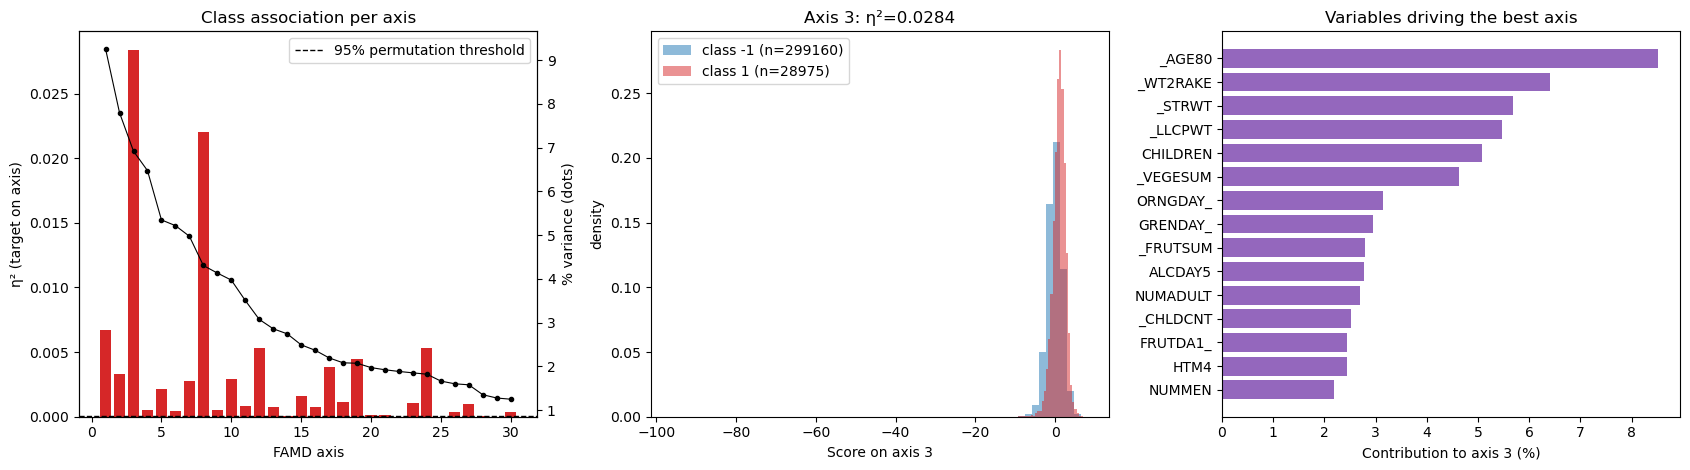

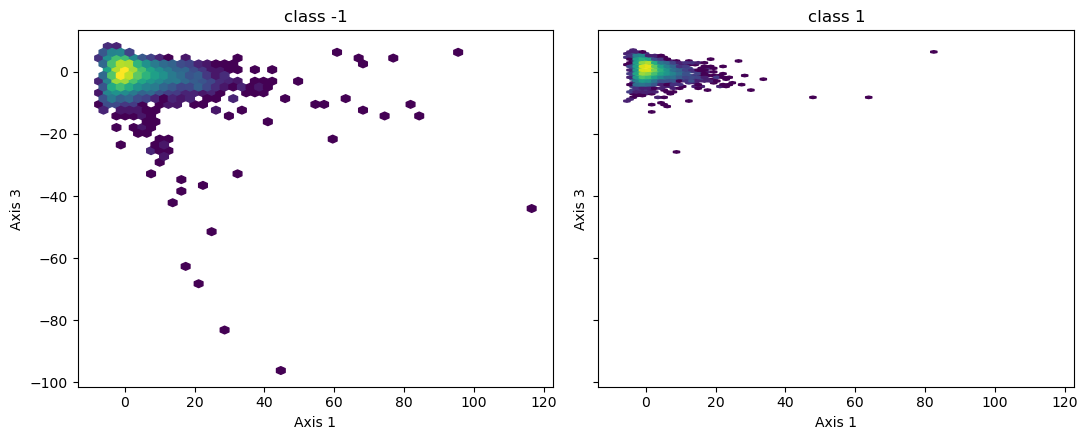

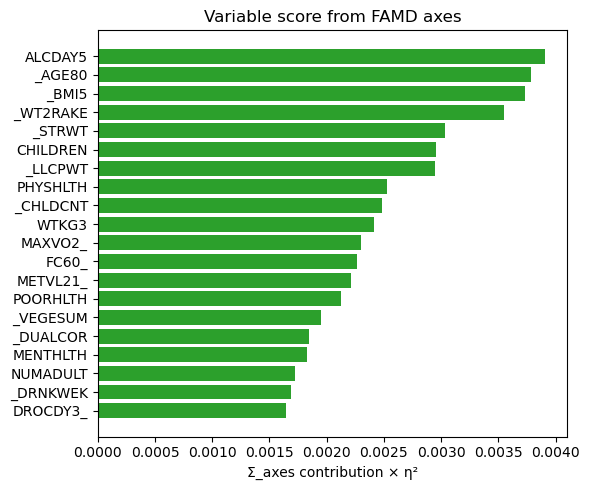

In [62]:
n_axes = 75          # number of leading axes to analyse
n_perm = 500

y_train = np.asarray(y_train)

M_id_name_map = {i: name for name, i in name_column_mapping_M.items()}
label = lambda i: M_id_name_map[i]

# --- explained variance (computed BEFORE truncating; valid for a full SVD) ---
expl_full = S**2 / (S**2).sum()

# --- truncate to the leading axes ---
r = min(n_axes, len(S))
U, S, Vh = U[:, :r], S[:r], Vh[:r]
expl = expl_full[:r]
F = U * S                                          # row scores on the r axes

if np.abs(U.mean(0)).max() > 1e-4:
    print("Warning: U columns are not centered -> Z was probably not column-centered")

# --- class indicators and eta^2 (fast form) ---
classes, yi = np.unique(y_train, return_inverse=True)
Ind = np.eye(len(classes))[yi]                     # (n, C)
n_c = Ind.sum(0)

def famd_eta2(U, Ind):
    return ((Ind.T @ U) ** 2 / Ind.sum(0)[:, None]).sum(0)

def variable_contributions(Vh, groups):
    V2 = Vh.T ** 2                                  # (p, r)
    return np.array([V2[g].sum(0) for g in groups])  # (n_variables, r)

eta2 = famd_eta2(U, Ind)
contrib = variable_contributions(Vh, groups)
var_score = contrib @ eta2

# --- permutation threshold: null distribution of the best axis ---
rng = np.random.default_rng(0)
null_max = np.array([famd_eta2(U, Ind[rng.permutation(len(yi))]).max() for _ in range(n_perm)])
thr = np.quantile(null_max, 0.95)
best = int(np.argmax(eta2))

print("U", U.shape, "S", S.shape, "Vh", Vh.shape, "y", y_train.shape)
print("eta2", eta2.shape, "contrib", contrib.shape)
print(f"Permutation threshold (95%, max over {r} axes): {thr:.5f}")
print("Axes above threshold (1-indexed):", [k + 1 for k in np.flatnonzero(eta2 > thr)] or "none")
print(f"Best axis: {best+1}  eta2={eta2[best]:.5f}  explained variance={expl[best]*100:.2f}%")
print("\nTop variables on the best axis:")
for i in np.argsort(-contrib[:, best])[:10]:
    print(f"  {label(i):<20s} contribution={contrib[i, best]*100:5.1f}%")

# ----------------------------------------------------------------------
# Figures
# ----------------------------------------------------------------------
cols = ['tab:blue', 'tab:red', 'tab:green', 'tab:orange']
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) eta2 per axis vs permutation threshold, with variance on a twin axis
k = np.arange(1, r + 1)
ax[0].bar(k, eta2, color=np.where(eta2 > thr, 'tab:red', 'lightgray'))
ax[0].axhline(thr, color='k', ls='--', lw=1, label='95% permutation threshold')
ax[0].set_xlabel('FAMD axis'); ax[0].set_ylabel('η² (target on axis)')
ax[0].set_title('Class association per axis'); ax[0].legend()
tw = ax[0].twinx(); tw.plot(k, expl * 100, 'k.-', lw=0.8); tw.set_ylabel('% variance (dots)')

# (b) distribution of the best axis, per class
for c, lab in enumerate(classes):
    ax[1].hist(F[yi == c, best], bins=60, density=True, alpha=0.5,
               color=cols[c], label=f'class {lab:g} (n={int(n_c[c])})')
ax[1].set_xlabel(f'Score on axis {best+1}'); ax[1].set_ylabel('density')
ax[1].set_title(f'Axis {best+1}: η²={eta2[best]:.4f}'); ax[1].legend()

# (c) variable contributions to the best axis
top = np.argsort(-contrib[:, best])[:15][::-1]
ax[2].barh([label(i) for i in top], contrib[top, best] * 100, color='tab:purple')
ax[2].set_xlabel(f'Contribution to axis {best+1} (%)')
ax[2].set_title('Variables driving the best axis')
plt.tight_layout(); plt.show()

# (d) axis 1 vs best axis, one density panel per class
if best != 0:
    fig, axs = plt.subplots(1, len(classes), figsize=(5.5 * len(classes), 4.5), sharex=True, sharey=True)
    for c, lab in enumerate(classes):
        axs[c].hexbin(F[yi == c, 0], F[yi == c, best], gridsize=50, bins='log', cmap='viridis')
        axs[c].set_title(f'class {lab:g}'); axs[c].set_xlabel('Axis 1'); axs[c].set_ylabel(f'Axis {best+1}')
    plt.tight_layout(); plt.show()

# (e) ranking of variables by class-related loading
order = np.argsort(-var_score)[:20][::-1]
plt.figure(figsize=(6, 5))
plt.barh([label(i) for i in order], var_score[order], color='tab:green')
plt.xlabel('Σ_axes contribution × η²'); plt.title('Variable score from FAMD axes')
plt.tight_layout(); plt.show()

dataset 3/3 done
Class balance: {-1.0: 299160, 1.0: 28975}
Variables tested: 157 (47 numeric, 110 categorical)
Candidates (mean effect >= 0.1 and q<0.05 in >= 70% of imputations): 53

rank  variable                type    effect    ± sd  sig freq  cand
   1  _AGE80                  num      0.474   0.000      100%  *
   2  FC60_                   num      0.468   0.000      100%  *
   3  MAXVO2_                 num      0.468   0.000      100%  *
   4  GENHLTH                 cat      0.266   0.000      100%  *
   5  _AGEG5YR                cat      0.237   0.000      100%  *
   6  _RFHLTH                 cat      0.235   0.000      100%  *
   7  EMPLOY1                 cat      0.231   0.000      100%  *
   8  _AGE_G                  cat      0.222   0.000      100%  *
   9  BPHIGH4                 cat      0.218   0.000      100%  *
  10  _RFHYPE5                cat      0.217   0.000      100%  *
  11  DIFFWALK                cat      0.215   0.000      100%  *
  12  CVDSTRK3       

C:\Users\jossd\AppData\Local\Temp\ipykernel_25532\1631912917.py:205: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[2].boxplot([E[:, i] for i in t15], vert=False, labels=[label(feats[i]) for i in t15])


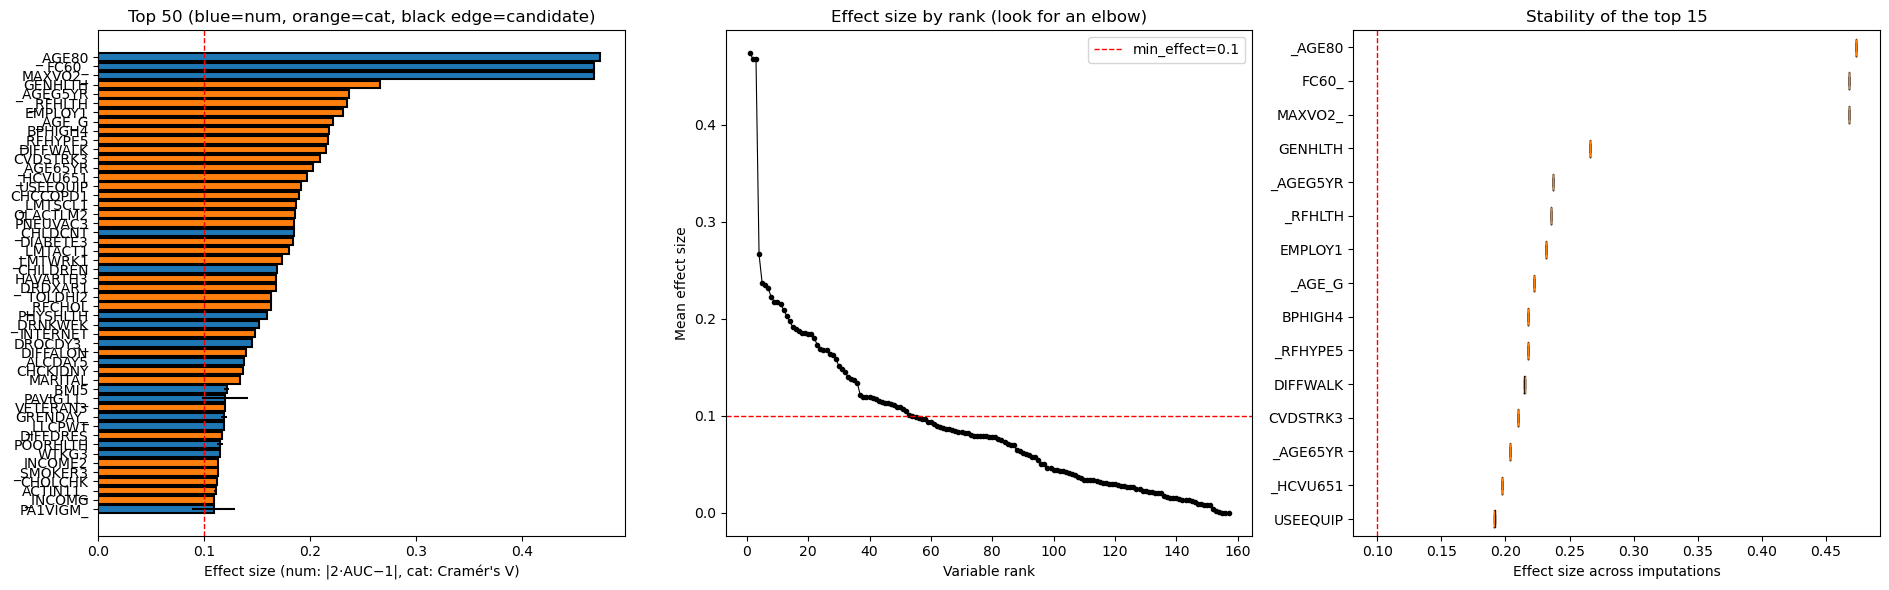

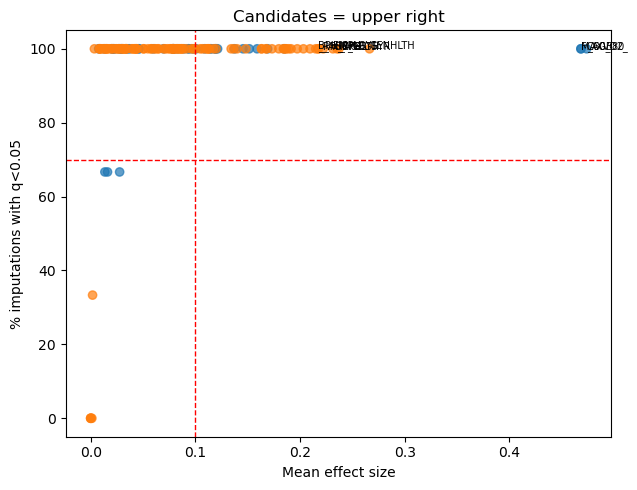

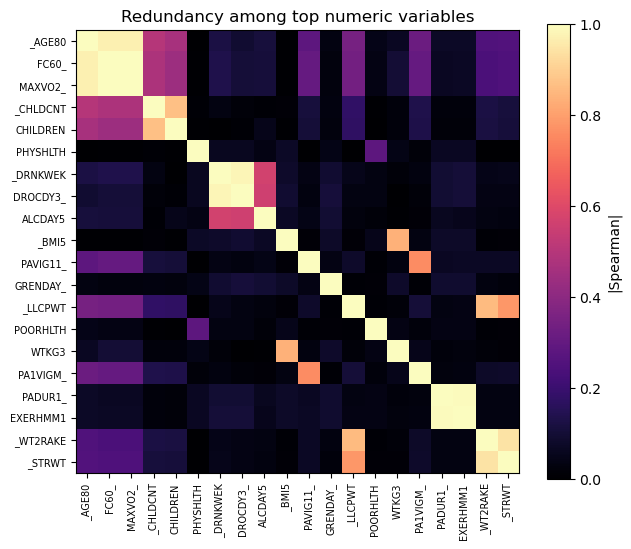


Candidate column indices: [np.int64(16), np.int64(35), np.int64(34), np.int64(52), np.int64(117), np.int64(101), np.int64(77), np.int64(119), np.int64(57), np.int64(103), np.int64(84), np.int64(61), np.int64(118), np.int64(102), np.int64(81), np.int64(65), np.int64(153), np.int64(80), np.int64(94), np.int64(21), np.int64(69), np.int64(151), np.int64(152), np.int64(6), np.int64(66), np.int64(109), np.int64(60), np.int64(105), np.int64(3), np.int64(23), np.int64(79), np.int64(22), np.int64(86), np.int64(9), np.int64(68), np.int64(71), np.int64(20), np.int64(44), np.int64(76), np.int64(27), np.int64(15), np.int64(85), np.int64(5), np.int64(19), np.int64(78), np.int64(124), np.int64(59), np.int64(140), np.int64(123), np.int64(46), np.int64(87), np.int64(82), np.int64(36)]


In [70]:
import math

# ----------------------------------------------------------------------
# INPUTS: edit this block
# ----------------------------------------------------------------------
# completed : list of m arrays in the ORIGINAL layout (your completed[k])
# target_col: index of the target column in those arrays (values -1 / 1)
# num_idx, cat_idx : your index lists (the target may still be in cat_idx, it is removed below)
# names     : optional dict {column index: label}
min_effect = 0.10     # minimum mean effect size to be a candidate
min_freq   = 0.70     # minimum share of imputations with q < alpha
alpha      = 0.05
top_show   = 50

num_feat = num_idx
cat_feat = cat_idx[:-1]  # remove target from categorical features

name_column_mapping_c = num_name_idx_map.copy()

for name, j in cat_name_idx_map.items():
    name_column_mapping_c[name] = j

col_name_map_c = {j: name for name, j in name_column_mapping_c.items()}


label = lambda j: col_name_map_c[j]


# ----------------------------------------------------------------------
# p-value helpers (no scipy)
# ----------------------------------------------------------------------
def _norm_sf2(z):
    return math.erfc(abs(z) / math.sqrt(2))

def _gammaincc(a, x):
    """Regularized upper incomplete gamma Q(a, x)."""
    if x <= 0:
        return 1.0
    lg = -x + a * math.log(x) - math.lgamma(a)
    if x < a + 1:
        term = s = 1.0 / a
        ap = a
        for _ in range(5000):
            ap += 1
            term *= x / ap
            s += term
            if abs(term) < abs(s) * 1e-14:
                break
        return max(0.0, 1.0 - s * math.exp(lg))
    b = x + 1 - a
    c, d = 1e300, 1.0 / b
    h = d
    for i in range(1, 5000):
        an = -i * (i - a)
        b += 2
        d = an * d + b
        d = 1e-300 if abs(d) < 1e-300 else d
        c = b + an / c
        c = 1e-300 if abs(c) < 1e-300 else c
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1) < 1e-14:
            break
    return min(1.0, math.exp(lg) * h)

def _chi2_sf(x, dof):
    return _gammaincc(dof / 2.0, x / 2.0)

def benjamini_hochberg(p):
    p = np.asarray(p, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adj = p[order] * m / np.arange(1, m + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(m)
    out[order] = np.minimum(adj, 1.0)
    return out

# ----------------------------------------------------------------------
# Tests
# ----------------------------------------------------------------------
def _ranks(x):
    _, inv, counts = np.unique(x, return_inverse=True, return_counts=True)
    avg = np.cumsum(counts) - (counts - 1) / 2.0
    return avg[inv], counts

def mann_whitney(x, pos):
    """pos: boolean mask of the positive class. Returns (AUC, two-sided p)."""
    n1, n0 = pos.sum(), (~pos).sum()
    N = n1 + n0
    r, counts = _ranks(x)
    U1 = r[pos].sum() - n1 * (n1 + 1) / 2.0
    auc = U1 / (n1 * n0)
    tie = (counts ** 3 - counts).sum() / (N * (N - 1))
    var = n1 * n0 / 12.0 * ((N + 1) - tie)
    if var <= 0:
        return 0.5, 1.0
    return auc, _norm_sf2((U1 - n1 * n0 / 2.0) / math.sqrt(var))

def chi2_cramers_v(x, pos):
    """Chi-square test of independence with the binary target. Returns (bias-corrected V, p)."""
    lv, xi = np.unique(x, return_inverse=True)
    L = len(lv)
    T = np.bincount(xi * 2 + pos.astype(int), minlength=2 * L).reshape(L, 2).astype(float)
    T = T[T.sum(1) > 0]
    n = T.sum()
    r, k = T.shape[0], 2
    if r < 2:
        return 0.0, 1.0
    expected = np.outer(T.sum(1), T.sum(0)) / n
    chi2 = ((T - expected) ** 2 / expected).sum()
    p = _chi2_sf(chi2, (r - 1) * (k - 1))
    phi2c = max(0.0, chi2 / n - (r - 1) * (k - 1) / (n - 1))      # Bergsma bias correction
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    denom = min(kc - 1, rc - 1)
    return (math.sqrt(phi2c / denom) if denom > 0 else 0.0), p

def univariate_filter(Xc, y):
    classes = np.unique(y)
    assert len(classes) == 2, "this filter expects a binary target"
    pos = (y == classes[1])
    feats, eff, pv = [], [], []
    for j in num_feat:
        auc, p = mann_whitney(Xc[:, j], pos)
        feats.append(j); eff.append(2 * abs(auc - 0.5)); pv.append(p)
    for j in cat_feat:
        v, p = chi2_cramers_v(Xc[:, j], pos)
        feats.append(j); eff.append(v); pv.append(p)
    q = benjamini_hochberg(pv)
    return np.array(feats), np.array(eff), np.array(pv), q

# ----------------------------------------------------------------------
# Run on every completed dataset and pool
# ----------------------------------------------------------------------
res = []
for k, Xc in enumerate(completed):
    res.append(univariate_filter(Xc, y_train))        # was: Xc[:, target_col]
    print(f"dataset {k+1}/{len(completed)} done", end="\r")
print()

feats   = res[0][0]
E       = np.array([r[1] for r in res])            # (m, n_features) effect sizes
Q       = np.array([r[3] for r in res])
eff_m, eff_s = E.mean(0), E.std(0)
freq    = (Q < alpha).mean(0)
is_num  = np.array([j in num_feat for j in feats])
cand    = (eff_m >= min_effect) & (freq >= min_freq)
order   = np.argsort(-eff_m)

# ----------------------------------------------------------------------
# Prints
# ----------------------------------------------------------------------
y0 = y_train
cls, cnt = np.unique(y0, return_counts=True)
print("Class balance:", {float(c): int(n) for c, n in zip(cls, cnt)})
print(f"Variables tested: {len(feats)} ({is_num.sum()} numeric, {(~is_num).sum()} categorical)")
print(f"Candidates (mean effect >= {min_effect} and q<{alpha} in >= {min_freq*100:.0f}% of imputations): {cand.sum()}\n")
print(f"{'rank':>4}  {'variable':<24}{'type':<6}{'effect':>8}{'± sd':>8}{'sig freq':>10}  cand")
for rnk, i in enumerate(order[:top_show], 1):
    print(f"{rnk:>4}  {label(feats[i]):<24}{'num' if is_num[i] else 'cat':<6}"
          f"{eff_m[i]:>8.3f}{eff_s[i]:>8.3f}{freq[i]*100:>9.0f}%  {'*' if cand[i] else ''}")
print("\nSignificant (q<alpha in all imputations) but weak (effect < min_effect):",
      [label(feats[i]) for i in order if freq[i] == 1 and eff_m[i] < min_effect][:15] or "none")
print("Unstable across imputations (0 < sig freq < 1):",
      [label(feats[i]) for i in order if 0 < freq[i] < 1][:15] or "none")

# ----------------------------------------------------------------------
# Redundancy among the top numeric candidates (absolute Spearman, first dataset)
# ----------------------------------------------------------------------
top_num = [i for i in order if is_num[i]][:20]
if len(top_num) >= 2:
    R = np.column_stack([_ranks(completed[0][:, feats[i]])[0] for i in top_num])
    C = np.abs(np.corrcoef(R, rowvar=False))
    pairs = [(C[a, b], a, b) for a in range(len(top_num)) for b in range(a + 1, len(top_num)) if C[a, b] > 0.8]
    print("\nHighly redundant numeric pairs (|Spearman| > 0.8), keep one of each:")
    for c, a, b in sorted(pairs, reverse=True)[:15]:
        print(f"  {label(feats[top_num[a]])}  ~  {label(feats[top_num[b]])}   ({c:.2f})")
    if not pairs:
        print("  none")

# ----------------------------------------------------------------------
# Figures
# ----------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(19, 6))

# (a) top variables: mean effect with sd over imputations, colored by type, edge = selected
top = order[:top_show][::-1]
colors = np.where(is_num[top], 'tab:blue', 'tab:orange')
ax[0].barh([label(feats[i]) for i in top], eff_m[top], xerr=eff_s[top], color=colors,
           edgecolor=np.where(cand[top], 'k', 'none'), linewidth=1.5)
ax[0].axvline(min_effect, color='r', ls='--', lw=1)
ax[0].set_xlabel('Effect size (num: |2·AUC−1|, cat: Cramér\'s V)')
ax[0].set_title(f'Top {top_show} (blue=num, orange=cat, black edge=candidate)')

# (b) sorted effect sizes of all variables: look for an elbow
srt = eff_m[order]
ax[1].plot(np.arange(1, len(srt) + 1), srt, 'k.-', lw=0.8)
ax[1].axhline(min_effect, color='r', ls='--', lw=1, label=f'min_effect={min_effect}')
ax[1].set_xlabel('Variable rank'); ax[1].set_ylabel('Mean effect size')
ax[1].set_title('Effect size by rank (look for an elbow)'); ax[1].legend()

# (c) spread over imputations for the top 15
t15 = order[:15][::-1]
ax[2].boxplot([E[:, i] for i in t15], vert=False, labels=[label(feats[i]) for i in t15])
ax[2].axvline(min_effect, color='r', ls='--', lw=1)
ax[2].set_xlabel('Effect size across imputations'); ax[2].set_title('Stability of the top 15')
plt.tight_layout(); plt.show()

# (d) effect vs significance frequency
plt.figure(figsize=(6.5, 5))
plt.scatter(eff_m, freq * 100, c=np.where(is_num, 'tab:blue', 'tab:orange'), alpha=0.7)
for i in order[:10]:
    plt.annotate(label(feats[i]), (eff_m[i], freq[i] * 100), fontsize=7)
plt.axvline(min_effect, color='r', ls='--', lw=1); plt.axhline(min_freq * 100, color='r', ls='--', lw=1)
plt.xlabel('Mean effect size'); plt.ylabel(f'% imputations with q<{alpha}')
plt.title('Candidates = upper right'); plt.tight_layout(); plt.show()

# (e) redundancy heatmap
if len(top_num) >= 2:
    plt.figure(figsize=(6.5, 5.5))
    plt.imshow(C, vmin=0, vmax=1, cmap='magma')
    plt.xticks(range(len(top_num)), [label(feats[i]) for i in top_num], rotation=90, fontsize=7)
    plt.yticks(range(len(top_num)), [label(feats[i]) for i in top_num], fontsize=7)
    plt.colorbar(label='|Spearman|'); plt.title('Redundancy among top numeric variables')
    plt.tight_layout(); plt.show()

selected = [feats[i] for i in order if cand[i]]
print("\nCandidate column indices:", selected)

# Variables Selection

In [ ]:
num_variables_selected = ["_AGE80", "FC60_", "PHYSHLTH", "_DRNKWEK", "_BMI5", "PAVIG11_", "GRENDAY_", "POORHLTH", "ORNGDAY_"]

cat_variables_selected = ["SEX", "GENHLTH", "EMPLOY1", "BPHIGH4", "DIFFWALK", "CVDSTRK3", "_HCVU651", "USEEQUIP", "CHCCOPD1", "_LMTSCL1",
                            "QLACTLM2", "PNEUVAC3", "DIABETE3", "_LMTACT1", "_LMTWRK1", "_DRDXAR1", "_RFCHOL", "DIFFALON", "CHCKIDNY", 
                            "MARITAL", "VETERAN3", "DIFFDRES", "INCOME2", "_SMOKER3", "_CHLDCNT" ]

# These variables may need to be excluded given that they may be correlated with the consequences of the disease, 
# so not predictive of the disease itself. For example, DIFFWALK and CVDSTRK3 may be consequences of heart disease rather than predictors.
var_to_exclude_mb = ["DIFFWALK", "CVDSTRK3", "USEEQUIP", "CHCCOPD1", "_LMTSCL1", "QLACTLM2", "PNEUVAC3", "_LMTACT1", "_LMTWRK1", "_DRDXAR1", 
                    "DIFFALON", "CHCKIDNY", "DIFFDRES"]

#Only necessary for numerical variables as categorical variables will simply have additional class and the fact that the missingness is probably not at random
name_missing_code_map = {"_AGE80": [None], "FC60_" : [99900], "PHYSHLTH":[77, 99], "_DRNKWEK":[99900], "_BMI5":[None], "PAVIG11_":[None],  "GRENDAY_":[None],
                        "POORHLTH":[77,99], "ORNGDAY_":[None]}
name_code_to_replace_map = { "PHYSHLTH": {88: 0}, "POORHLTH": {88:0}}



 

### Loading the data

In [ ]:

ROOT = Path.cwd().parent
sys.path.append(str(ROOT))
data_dir = f"{ROOT}/data"

def load_data(data_dir):
    x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_dir)

    # getting the feature names since load_csv_data drops the header 
    with open(os.path.join(data_dir, "x_train.csv")) as train_data_reader: 
        header = train_data_reader.readline().strip().split(",")

    feature_names = np.array(header[1:])
    name_column_index_mapping = {name: j for j, name in enumerate(feature_names)}
    return x_train, x_test, y_train, name_column_index_mapping

### Variable Extraction
First Extract the columns of interest from the original dataset and replace missing codes with np.nan and encode the features that needs to be reencoded.


In [ ]:
def sub_set_columns(X, name_col_map, num_names, cat_names):
    """
    Subsample the columns of X given the names of the numeric and categorical variables. Returns the subsampled X, a mapping of names to indices, a mapping of indices to names and the numeric and categorical indices. 
    """
    cat_name_idx_map = {}
    num_name_idx_map = {}

    num_idx0 = []
    cat_idx0 = []
    k=0
    for num_n in num_names:
        num_idx0.append(name_col_map[num_n])
        num_name_idx_map[num_n] = k
        k+=1
    for cat_n in cat_names:
        cat_idx0.append(name_col_map[cat_n])
        cat_name_idx_map[cat_n] = k
        k+=1
    
    num_idx=list(num_name_idx_map.values())
    cat_idx=list(cat_name_idx_map.values())

    name_idx_map = {**num_name_idx_map, **cat_name_idx_map}
    idx_name_map = {v: k for k, v in name_idx_map.items()}
    return X[:, num_idx0 + cat_idx0], name_idx_map, idx_name_map, num_idx, cat_idx, num_idx0, cat_idx0, cat_name_idx_map, num_name_idx_map

def replace_missing_codes(X, name_missing_code_map, name_col_map):
    for name,codes in name_missing_code_map.items():
        col_idx = name_col_map[name]
        for code in codes:
            if code is not None:
                X[X[:, col_idx] == code, col_idx] = np.nan
    return X

def replace_codes(X, name_code_to_replace_map, name_col_map):
    for name, code_map in name_code_to_replace_map.items():
        col_idx = name_col_map[name]
        for old_code, new_code in code_map.items():
            X[X[:, col_idx] == old_code, col_idx] = new_code
    return X

### Imputation of missing values based on MICE
In case it is the testing set, use the training set to impute the values 

In [ ]:
def fit_codes(Xraw, cat_idx):
    X = np.asarray(Xraw, dtype=float).copy()
    levels, K = {}, [0] * X.shape[1]
    for j in cat_idx:
        obs = ~np.isnan(X[:, j])
        lv = np.unique(X[obs, j])
        X[obs, j] = np.searchsorted(lv, X[obs, j])
        levels[j], K[j] = lv, len(lv)
    return X, levels, K

def transform_codes(Xraw, levels, K):
    X = np.asarray(Xraw, dtype=float).copy()

    for j, values in levels.items():
        observed = ~np.isnan(X[:, j])
        raw_values = X[observed, j]

        positions = np.searchsorted(values, raw_values)
        valid = (
            (positions < values.size)
            & (values[np.minimum(positions, values.size - 1)] == raw_values)
        )

        observed_rows = np.flatnonzero(observed)

        # Unseen test categories become missing.
        X[observed_rows[~valid], j] = np.nan
        X[observed_rows[valid], j] = positions[valid]

    return X

def from_codes(Xi, levels):
    out = Xi.copy()
    for j, lv in levels.items():
        out[:, j] = lv[Xi[:, j].astype(int)]
    return out

# ----------------------------------------------------------------------
# 2. Imputation models (all observed rows are used)
# ----------------------------------------------------------------------

def _impute_num(A_fit, y_fit, A_miss, rng, ridge=1e-4):
    n, p = A_fit.shape

    G = A_fit.T @ A_fit
    Xt_y = A_fit.T @ y_fit

    scale = ridge * np.trace(G) / p
    G.flat[::p + 1] += scale
    G[0, 0] -= scale

    L = np.linalg.cholesky(G)

    beta_hat = np.linalg.solve(
        L.T,
        np.linalg.solve(L, Xt_y),
    )

    residuals = y_fit - A_fit @ beta_hat
    sigma2 = (residuals @ residuals) / rng.chisquare(max(n - p, 1))

    beta = beta_hat + np.sqrt(sigma2) * np.linalg.solve(
        L.T,
        rng.standard_normal(p),
    )

    return (
        A_miss @ beta
        + np.sqrt(sigma2) * rng.standard_normal(A_miss.shape[0])
    )


def _impute_cat(A_fit, y_fit, A_miss, K, rng, lam=1.0):
    n_obs = A_fit.shape[0]

    bootstrap_indices = rng.integers(
        0,
        n_obs,
        size=n_obs,
    )
    counts = np.bincount(
        bootstrap_indices,
        minlength=n_obs,
    )

    selected = counts > 0
    As = A_fit[selected]
    labels = y_fit[selected].astype(np.int64)
    weights = counts[selected].astype(A_fit.dtype, copy=False)

    weighted_As = As * weights[:, None]
    XtX = As.T @ weighted_As

    XtY = np.zeros(
        (As.shape[0], K),
        dtype=A_fit.dtype,
    )
    XtY[np.arange(As.shape[0]), labels] = weights
    XtY = As.T @ XtY

    p = XtX.shape[0]
    XtX.flat[::p + 1] += lam
    XtX[0, 0] -= lam

    W = np.linalg.solve(XtX, XtY)

    P = np.clip(A_miss @ W, 1e-3, None)
    P /= P.sum(axis=1, keepdims=True)

    u = rng.random(A_miss.shape[0])
    draw = np.sum(P.cumsum(axis=1) < u[:, None], axis=1)

    return np.minimum(draw, K - 1)

def fill_numba(D, Xi, j, is_num, start, k, mu, sd):
    n = Xi.shape[0]

    if is_num:
        for i in range(n):
            D[i, start] = (Xi[i, j] - mu[j]) / sd[j]
    else:
        for i in range(n):
            value = int(Xi[i, j])

            for c in range(1, k):
                D[i, start + c - 1] = 1.0 if value == c else 0.0

# ----------------------------------------------------------------------
# 3. One chain = one completed dataset
# ----------------------------------------------------------------------

def _chain_train_test(
    X_train,
    X_test,
    types,
    K,
    n_iter,
    seed,
    max_fit_rows,
    n_train,
):
    print(f"Imputing missing values in the test and training set")
    t0 = timeit.default_timer()
    rng = np.random.default_rng(seed)

    X = np.vstack((X_train, X_test)).astype(float, copy=True)

    n_total, d = X.shape
    train_rows = np.arange(n_train)
    test_rows = np.arange(n_train, n_total)

    missing = np.isnan(X)

    order = [
        j
        for j in np.argsort(
            missing.sum(axis=0),
            kind="stable",
        )
        if missing[:, j].any()
    ]

    slices = []
    start = 1

    for variable_type, k in zip(types, K):
        width = 1 if variable_type == "num" else max(k - 1, 0)
        slices.append(slice(start, start + width))
        start += width

    keep = [
        np.concatenate(
            [[0]]
            + [
                np.arange(s.start, s.stop)
                for i, s in enumerate(slices)
                if i != j
            ]
        )
        for j in range(d)
    ]

    # These statistics must be learned from training rows only.
    mu = np.array([
        np.nanmean(X_train[:, j])
        if types[j] == "num"
        else 0.0
        for j in range(d)
    ])

    sd = np.array([
        np.nanstd(X_train[:, j]) + 1e-12
        if types[j] == "num"
        else 1.0
        for j in range(d)
    ])

    is_num = np.array(
        [variable_type == "num" for variable_type in types],
        dtype=np.bool_,
    )

    slice_start = np.array(
        [s.start for s in slices],
        dtype=np.int64,
    )

    K_array = np.asarray(K, dtype=np.int64)

    # Initialize every missing value from training observed values only.
    for j in order:
        train_observed = train_rows[~missing[:n_train, j]]

        if train_observed.size == 0:
            raise ValueError(
                f"Column {j} has no observed training values."
            )

        train_missing = np.flatnonzero(missing[:, j])

        X[train_missing, j] = rng.choice(
            X[train_observed, j],
            size=train_missing.size,
        )

    D = np.ones((n_total, start), dtype=float)

    for j in range(d):
        fill_numba(
            D,
            X,
            j,
            is_num[j],
            slice_start[j],
            K_array[j],
            mu,
            sd,
        )

    for _ in range(n_iter):
        for j in order:
            train_observed = train_rows[~missing[:n_train, j]]

            if train_observed.size > max_fit_rows:
                fit_rows = rng.choice(
                    train_observed,
                    size=max_fit_rows,
                    replace=False,
                )
            else:
                fit_rows = train_observed

            # Only training rows enter the fitted model.
            A_fit = D[np.ix_(fit_rows, keep[j])]
            y_fit = X[fit_rows, j]

            train_missing = np.flatnonzero(
                missing[:n_train, j]
            )

            test_missing = n_train + np.flatnonzero(
                missing[n_train:, j]
            )

            prediction_rows = np.concatenate(
                (train_missing, test_missing)
            )

            if prediction_rows.size == 0:
                continue

            A_missing = D[
                np.ix_(prediction_rows, keep[j])
            ]

            if types[j] == "num":
                draws = _impute_num(
                    A_fit,
                    y_fit,
                    A_missing,
                    rng,
                )
            else:
                draws = _impute_cat(
                    A_fit,
                    y_fit,
                    A_missing,
                    K[j],
                    rng,
                )

            X[prediction_rows, j] = draws

            fill_numba(
                D,
                X,
                j,
                is_num[j],
                slice_start[j],
                K_array[j],
                mu,
                sd,
            )
    print(f"Done in {timeit.default_timer() - t0:.1f} seconds")
    return X[:n_train], X[n_train:]

def mice_train_test(
    X_train,
    X_test,
    num_idx,
    cat_idx,
    m=3,
    n_iter=5,
    seed=67,
    max_fit_rows=75000,
):
    X_train_codes, levels, K = fit_codes(
        X_train,
        cat_idx,
    )

    X_test_codes = transform_codes(
        X_test,
        levels,
        K,
    )

    d = X_train_codes.shape[1]

    types = [
        "num" if j in num_idx else "cat"
        for j in range(d)
    ]

    n_train = X_train_codes.shape[0]
    master = np.random.default_rng(seed)

    completed_train = []
    completed_test = []

    for _ in range(m):
        train_i, test_i = _chain_train_test(
            X_train_codes,
            X_test_codes,
            types,
            K,
            n_iter,
            int(master.integers(2**32)),
            max_fit_rows,
            n_train,
        )

        completed_train.append(
            from_codes(train_i, levels)
        )
        completed_test.append(
            from_codes(test_i, levels)
        )

    return completed_train, completed_test

### Formating the design matrix

In [ ]:
def one_hot_encode_X(Xi, i, num_idx, cat_dict, num_dict, name_col_map_X):
    X1 = [np.ones_like(Xi[:,0]), Xi[:, num_idx]]
    if i==0:
        n = X1[1].shape[1] + 1
        num_dict = {n:j+1 for n,j in num_dict.items()}

    for name, j in cat_dict.items():
        values, inverse = np.unique(
            Xi[ :, j],
            return_inverse=True,
        )
        n_values = len(values)
        one_hot_columns = np.eye(n_values)[inverse]
    
        X1.append(one_hot_columns)        
        if i == 0:
            for value in values:
                feature_name = f"{name}_{value}"
                name_column_mapping_X[feature_name] = n
                n += 1
    if i == 0:
        name_column_mapping_X = {**num_dict, **name_column_mapping_X}
    return np.hstack(X1)

### Preprocessing function
Combines each earlier steps, returning the imputed training and testing design matrices

In [ ]:
import timeit

def preprocessing(data_dir, num_variables_selected, cat_variables_selected, name_missing_code_map, name_code_to_replace_map):
    print("Loading data...")
    start = timeit.default_timer()
    x_train, x_test, y_train, name_col_map = load_data(data_dir)
    t0 = timeit.default_timer()
    print(f"Data loaded in {t0 - start:.2f} seconds.")
    print("Encoding missing values and replacing codes...")
    x_train = replace_missing_codes(x_train, name_missing_code_map, name_col_map)
    x_train = replace_codes(x_train, name_code_to_replace_map, name_col_map)
    x_test = replace_missing_codes(x_test, name_missing_code_map, name_col_map)
    x_test = replace_codes(x_test, name_code_to_replace_map, name_col_map)
    t1 = timeit.default_timer()
    print(f"Missing values encoded and codes replaced in {t1 - t0:.2f} seconds.")
    print("Extracting selected columns...")
    X_tr_raw, name_idx_map, idx_name_map, num_idx, cat_idx, num_idx0, cat_idx0, cat_name_idx_map, num_name_idx_map = sub_set_columns(x_train, name_col_map, num_variables_selected, cat_variables_selected)
    X_te_raw = x_test[:, num_idx0 + cat_idx0]
    t2 = timeit.default_timer()
    print(f"Selected columns extracted in {t2 - t1:.2f} seconds.")
    print("Performing MICE imputation...")
    completed, completed_test = mice_train_test(X_tr_raw, X_te_raw, num_idx, cat_idx, m=2, n_iter=5, seed=67, max_fit_rows=75000)
    t3 = timeit.default_timer()
    print(f"MICE imputation completed in {t3 - t2:.2f} seconds.")
    print("One-hot encoding completed datasets...")
    name_column_mapping_X = {"Intercept":0}
    X1_tr = [one_hot_encode_X(Xi, i, num_idx, cat_name_idx_map, num_name_idx_map, name_column_mapping_X) for i, Xi in enumerate(completed)]
    X1_te = [one_hot_encode_X(Xi, i+1, num_idx, cat_name_idx_map, num_name_idx_map, name_column_mapping_X) for i, Xi in enumerate(completed_test)]
    t4 = timeit.default_timer()
    print(f"One-hot encoding completed in {t4 - t3:.2f} seconds.")
    print(f"Total preprocessing time: {t4 - start:.2f} seconds.")
    return X1_tr, X1_te, y_train, name_column_mapping_X
    
